# COS711 Assignment 2: Improving the Kaggle score
Our first Kaggle upload scored **0.33** on the public leaderboard (rank 789), below the **0.396** we measured
locally. This notebook tests five changes meant to close that gap and raise the score, and measures each one
locally **before** anything is uploaded:

1. **A fair local estimate**: score all 5 fold models on their own held-out images with tuned post-processing,
   to see whether 0.396 was simply a lucky fold.
2. **Small filaments**: keep small predicted blobs when the model is confident about them.
3. **Ensembles**: average the probability maps of several models.
4. **Continuity of large filaments**: add the clDice loss, which penalises a filament broken into pieces.
5. **More training data**: retrain on all 707 labelled images.

Every code cell has a **What & why** note above it and an **Interpretation** note below it, written from the
real outputs. The heavy work (inference, training) was done by `run_improve.py`; this notebook reads its saved
results from `runs/improve/`, so it runs in a few minutes without retraining anything.

**Rules that keep the numbers honest**
- Choices (thresholds, which models, which epoch count) are made on **monitor** images only.
- **Report** images are never used for a choice; their PQ is the number we quote.
- A model is only scored on images it never trained on.

> Scope note: ensembles, clDice and the small-blob rule are *Enhancement* work (Member 3's section in the group
> plan). They are here because they were needed to decide what to upload; the group should decide where they go
> in the report.

## 0. Setup
**What & why.** Load every result file written by `run_improve.py`, so that each number below comes from a saved
run and not from memory.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
import filament_pipeline as fp
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 90)
IMP, PREPARED = Path("runs/improve"), "../data_prep/prepared"
load = lambda f: json.load(open(IMP / f))
cv, small, cld, alld, subs = load("cv.json"), load("small.json"), load("cldice.json"), load("alldata.json"), load("subs.json")
ens = pd.DataFrame(load("ensemble.json")["table"])
byfold, cvsum = pd.read_csv(IMP / "cv_report_by_fold.csv"), pd.read_csv(IMP / "cv_summary.csv")
pp_old = json.load(open("runs/postprocess.json"))
SHORT = {"arch_smp_unet_efficientnet-b3": "EffB3 s42", "seed2_smp_unet_efficientnet-b3": "EffB3 s7",
         "lr_0.0001_smp_unet_efficientnet-b3": "EffB3 lr1e-4", "loss_bce_dice": "R34 U-Net", "arch_smp_unetpp": "R34 U-Net++",
         "loss_focal_dice": "R34 U-Net focal", "arch_smp_deeplabv3p": "R34 DeepLabV3+"}
print("result files:", sorted(p.name for p in IMP.glob("*.json")))
print("probability maps cached:", sum(1 for _ in (IMP / "probs").glob("*/*.png")))

result files: ['alldata.json', 'alldata_first_try_12ep.json', 'cldice.json', 'cv.json', 'ensemble.json', 'small.json', 'subs.json']
probability maps cached: 2665


**Interpretation.** All result files are present, plus 2,665 cached probability maps (one per model per
validation image), so every table below is read from saved runs. `alldata_first_try_12ep.json` is an earlier
version of section 6 that was replaced when a second epoch count was added; it is kept for the record.

## 1. Starting point: local 0.396 vs Kaggle 0.33
**What & why.** Put the three numbers we had side by side. The gap between them is what this notebook tries
to explain and close.

In [2]:
first = [r for r in pp_old["report_table"] if r["setting"] == "tuned" and r["tta"]][0]
start = pd.DataFrame([
    dict(estimate="Local: fold-0 report images (model of the first upload)", PQ=round(first["pq"], 3), images="99"),
    dict(estimate="Kaggle public leaderboard (first upload, rank 789)", PQ=0.33, images="~90 (half of 180)"),
    dict(estimate="Human agreement: one annotator scored against the others", PQ=0.343, images="93 annotation sets")])
print(start.to_string(index=False))

                                                estimate    PQ             images
 Local: fold-0 report images (model of the first upload) 0.396                 99
      Kaggle public leaderboard (first upload, rank 789) 0.330  ~90 (half of 180)
Human agreement: one annotator scored against the others 0.343 93 annotation sets


**Interpretation.** The leaderboard gave **0.066 less** than our local number, and slightly less than two
human experts agree with each other (0.343). Two explanations are possible, and the next section tests the first:
1. **0.396 was a lucky fold.** Fold 0 is where every choice was made, so it may be the friendliest fold.
2. **The public leaderboard is small.** It scores about half of the 180 test images (~90), so it is noisy too.

A third explanation, a different kind of test image, is unlikely: the test images cover the same years
(2011–2022) and the same six telescopes in similar proportions as the training images.

## 2. A fair local estimate: all 5 folds, tuned post-processing, TTA
**What & why.** The 0.396 comes from **one** fold (fold 0), the fold on which every choice was made. Our 5-fold
number (0.298) used the default post-processing (threshold 0.5, drop blobs under 60 px) and no TTA, so neither
number is a fair estimate of the submitted pipeline. Here each of the 5 fold models is scored on **its own**
report images (never used for early stopping) under four conditions: default or tuned post-processing, each
with and without flip TTA. The post-processing is re-tuned on the **pooled monitor images of all 5 folds**
(200 images) instead of fold 0's 40.

Pooled-monitor tuning (200 images), top 5 of 20 settings:
                   setting     pq     sq     rq
threshold=0.5,min_area=500 0.3652 0.6673 0.5473
threshold=0.6,min_area=500 0.3642 0.6690 0.5444
threshold=0.7,min_area=500 0.3620 0.6697 0.5405
threshold=0.4,min_area=500 0.3580 0.6651 0.5383
threshold=0.5,min_area=800 0.3545 0.6685 0.5303

Report PQ across the 5 folds:
                              setting TTA  mean PQ    std  pooled PQ
cv-tuned (threshold=0.5,min_area=500)  no   0.3523 0.0169     0.3521
cv-tuned (threshold=0.5,min_area=500) yes   0.3683 0.0186     0.3682
                     default (0.5/60)  no   0.2975 0.0110     0.2973
                     default (0.5/60) yes   0.3160 0.0108     0.3159
                fold0-tuned (0.6/500)  no   0.3541 0.0178     0.3539
                fold0-tuned (0.6/500) yes   0.3698 0.0211     0.3699


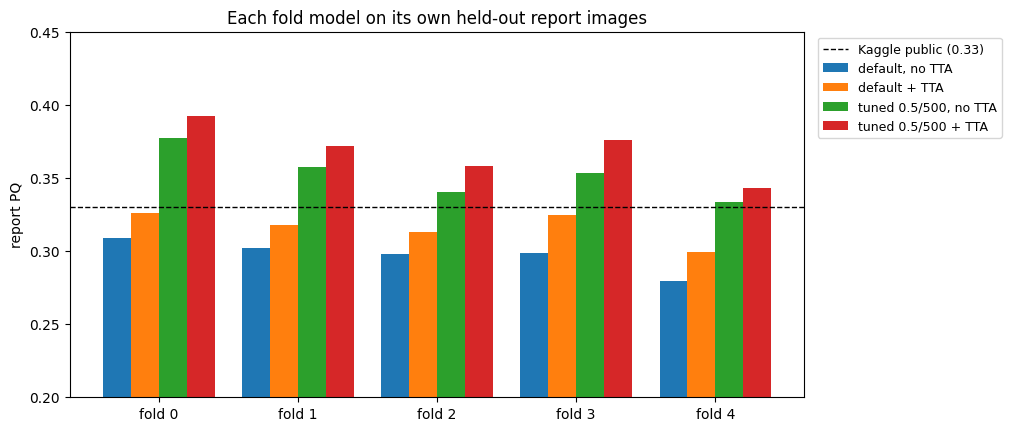

In [3]:
g = pd.DataFrame([dict(setting=k, **v) for k, v in cv["monitor_grid"].items()]).sort_values("pq", ascending=False)
print("Pooled-monitor tuning (200 images), top 5 of 20 settings:")
print(g[["setting", "pq", "sq", "rq"]].head(5).round(4).to_string(index=False))
cvt = [s for s in cvsum.setting.unique() if s.startswith("cv-tuned")][0]
tab = cvsum.assign(TTA=cvsum.tta.map({0: "no", 1: "yes"}))[["setting", "TTA", "mean", "std", "pooled_pq"]]
print("\nReport PQ across the 5 folds:")
print(tab.rename(columns={"mean": "mean PQ", "std": "std", "pooled_pq": "pooled PQ"}).round(4).to_string(index=False))
piv = byfold.pivot_table(index="fold", columns=["setting", "tta"], values="pq")
fig, ax = plt.subplots(figsize=(10, 4.2), constrained_layout=True)
conds = [("default (0.5/60)", 0, "default, no TTA"), ("default (0.5/60)", 1, "default + TTA"),
         (cvt, 0, "tuned 0.5/500, no TTA"), (cvt, 1, "tuned 0.5/500 + TTA")]
w = 0.2
for i, (s, t, lab) in enumerate(conds):
    ax.bar(piv.index + (i - 1.5) * w, piv[(s, t)], w, label=lab)
ax.axhline(0.33, color="k", ls="--", lw=1, label="Kaggle public (0.33)")
ax.set_xticks(piv.index); ax.set_xticklabels([f"fold {f}" for f in piv.index]); ax.set_ylim(0.2, 0.45)
ax.set_ylabel("report PQ"); ax.set_title("Each fold model on its own held-out report images")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.show()

**Interpretation.**
- **Check first:** default settings without TTA give **0.2975 ± 0.0110**, exactly the 5-fold result of the
  experimental setup (0.298 ± 0.011). The cached maps reproduce the earlier pipeline.
- **The fair estimate of the submitted pipeline is 0.368 ± 0.019** (tuned 0.5/500 + TTA), not 0.396. Fold 0
  is the best fold (0.393); fold 4 is the worst (0.343).
- **Tuning on 200 monitor images agrees with tuning on 40.** The best setting is 0.5/500 (monitor 0.365),
  with 0.6/500 (0.364) and 0.7/500 (0.362) almost tied. The minimum area of 500 px is what matters; the
  threshold hardly does. On report the two give the same PQ (0.368 vs 0.370).
- **What each step is worth, averaged over 5 folds:** tuned post-processing +0.055 (0.298 → 0.352), then
  TTA +0.016 (→ 0.368).
- **Against Kaggle:** 0.33 is 0.038 below the 5-fold mean, about 2 fold standard deviations. Every fold model
  scores above 0.33 on its own held-out images, and the lowest is 0.343. So the "lucky fold" explains about
  40% of the gap (0.028 of 0.066). The rest is most likely noise from the ~90-image public subset, but we
  cannot prove that locally.

## 3. Small filaments: a confidence-aware size filter
**What & why.** The tuned post-processing drops every predicted blob under 500 px, because most small
predictions were wrong. But real small filaments exist and are found only 25% of the time (error analysis in
`segmentation_results.ipynb`). The rule tested here keeps a blob of `small_area`–500 px **if its mean
probability is at least `small_conf`**, so only the blobs the model is sure about come back. The grid
(3 sizes × 5 confidence levels) is scored on the pooled monitor images; only the best setting is scored on the
report images.

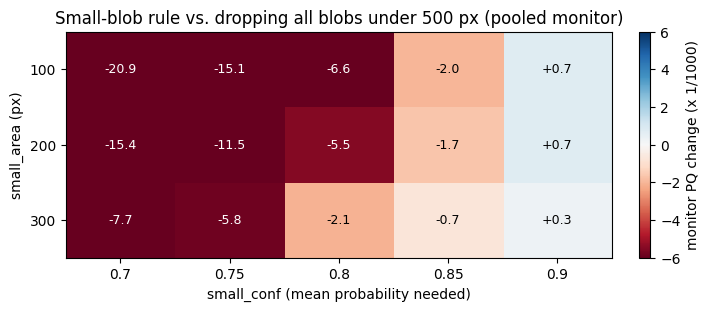

monitor PQ: rule off 0.3652 | best (small_area=100,small_conf=0.9) 0.3659
report  PQ: rule off 0.3682 (TP 3537, FP 3427) | best 0.3709 (TP 3643, FP 3611)
adopted (needs > +0.002 on monitor): False


In [4]:
sg = pd.DataFrame([dict(setting=k, **v) for k, v in small["monitor_grid"].items()])
off = small["monitor_grid"]["off"]["pq"]
sg = sg[sg.setting != "off"].copy()
sg["small_area"] = sg.setting.str.extract(r"small_area=(\d+)")[0].astype(int)
sg["small_conf"] = sg.setting.str.extract(r"small_conf=([\d.]+)")[0].astype(float)
heat = sg.pivot(index="small_area", columns="small_conf", values="pq") - off
fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
im = ax.imshow(heat.values * 1000, cmap="RdBu", vmin=-6, vmax=6, aspect="auto")
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns); ax.set_xlabel("small_conf (mean probability needed)")
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index); ax.set_ylabel("small_area (px)")
for (i, j), v in np.ndenumerate(heat.values * 1000):
    ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 4 else "black")
fig.colorbar(im, ax=ax, label="monitor PQ change (x 1/1000)")
ax.set_title("Small-blob rule vs. dropping all blobs under 500 px (pooled monitor)")
plt.show()
rep = small["report"]; b = small["best"]
print(f"monitor PQ: rule off {off:.4f} | best ({b}) {small['monitor_grid'][b]['pq']:.4f}")
print(f"report  PQ: rule off {rep['off']['pq']:.4f} (TP {rep['off']['tp']}, FP {rep['off']['fp']}) | "
      f"best {rep[b]['pq']:.4f} (TP {rep[b]['tp']}, FP {rep[b]['fp']})")
print("adopted (needs > +0.002 on monitor):", small["helps_on_monitor"])

**Interpretation.**
- **Keeping small blobs hurts unless the model is very sure.** Every setting with `small_conf` ≤ 0.85 lowers
  monitor PQ, by up to 0.021. Only `small_conf` = 0.9 helps, by +0.0007.
- On report the best setting gains +0.0027: 106 more true filaments, but 184 more false ones.
- **Not adopted.** The gain on monitor is below the +0.002 bar set before the test, and it is far smaller than
  the seed-to-seed spread (section 4). The model's confidence does not separate real small filaments from
  false ones well. Many small filaments are also drawn by only one annotator, so a correct small detection is
  often scored as false against the other annotator's outline.

## 4. Ensembles: averaging several models
**What & why.** Averaging the probability maps of several models usually removes some of each model's random
mistakes. To test this fairly we use only the **7 models trained with fold 0 held out** (from the experimental
setup sweep), so no model has seen a fold-0 image. For each model or set of models the post-processing is
tuned on fold-0 monitor (threshold 0.5/0.6/0.7 × min_area 300/500/800) and scored on fold-0 report. All maps use
flip TTA. "Greedy" adds models one at a time while monitor PQ rises by more than 0.002. The cost is inference
time: each model adds its own seconds per image.

               kind                                          models      pp  monitor_pq  report_pq  report_rq  report_sq  seconds_per_image
             single                                       EffB3 s42 0.6/500      0.3815     0.3961     0.5884     0.6731               1.82
             single                                        EffB3 s7 0.6/500      0.3811     0.3755     0.5579     0.6731               1.82
             single                                    EffB3 lr1e-4 0.7/500      0.3803     0.3861     0.5717     0.6754               1.83
             single                                       R34 U-Net 0.5/500      0.3579     0.3730     0.5538     0.6735               1.34
             single                                     R34 U-Net++ 0.5/500      0.3594     0.3639     0.5423     0.6711               3.35
             single                                 R34 U-Net focal 0.5/500      0.3661     0.3636     0.5448     0.6674               1.34
             single 

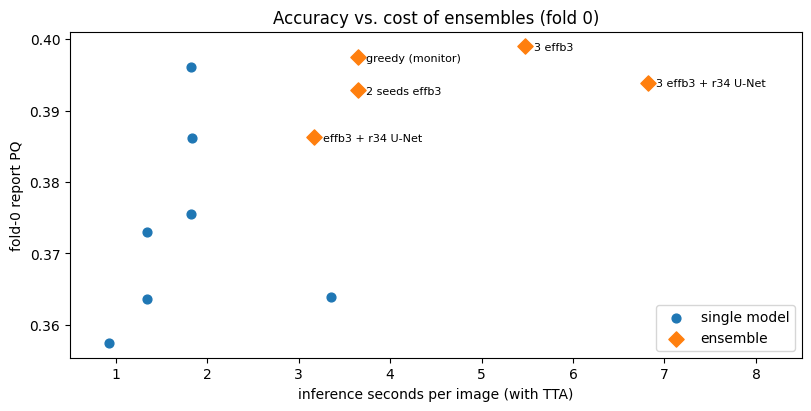

In [5]:
t = ens.assign(models=ens.models.apply(lambda m: " + ".join(SHORT[x] for x in m)),
               pp=ens.pp.apply(lambda p: f"{p['threshold']}/{p['min_area']}"))
print(t[["kind", "models", "pp", "monitor_pq", "report_pq", "report_rq", "report_sq", "seconds_per_image"]]
      .round(4).to_string(index=False))
singles = t[t.kind == "single"]
effb3 = singles[singles.models.str.startswith("EffB3")]
print(f"\nEffB3 singles on report: mean {effb3.report_pq.mean():.4f}, range {effb3.report_pq.min():.4f}-{effb3.report_pq.max():.4f}")
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.scatter(singles.seconds_per_image, singles.report_pq, label="single model", s=40)
multi = t[t.kind != "single"]
ax.scatter(multi.seconds_per_image, multi.report_pq, label="ensemble", s=60, marker="D")
for _, r in multi.iterrows():
    ax.annotate(r.kind, (r.seconds_per_image, r.report_pq), xytext=(6, -3), textcoords="offset points", fontsize=8)
ax.set_xlabel("inference seconds per image (with TTA)"); ax.set_ylabel("fold-0 report PQ")
ax.set_xlim(0.5, 8.5); ax.legend(loc="lower right"); ax.set_title("Accuracy vs. cost of ensembles (fold 0)")
plt.show()

**Interpretation.**
- **Single models have a "seed lottery".** Three EfficientNet-B3 runs that differ only by seed or learning rate
  score **0.376–0.396** on the same report images (mean 0.386). Our first submission's model (seed 42) was the
  luckiest of the three.
- **An ensemble removes most of that lottery.** Averaging the three EfficientNet-B3 runs gives **0.399**:
  +0.013 over the average single run and +0.003 over the luckiest. Its monitor PQ (0.387) is also above every
  single model (≤ 0.382). The gain comes from recognition (RQ 0.592); the outline quality (SQ ≈ 0.674) does
  not change.
- **Weaker models dilute the ensemble.** Adding the ResNet34 U-Net (0.373 alone) lowers the result (0.394 for
  four models; 0.386 for EffB3 s42 + R34).
- **Greedy selection on monitor** stops at two models (s42 + lr1e-4), with report 0.3975, essentially the same
  as the three-model ensemble.
- **Cost:** each model adds ~1.8 s per image, so three models take 5.5 s instead of 1.8 s per image. For 180 test
  images that is 16 minutes instead of 5, acceptable for a submission.
- **Consequence for Kaggle:** an ensemble of the **5 fold models** is the same idea with even more variety (each
  model saw a different 80% of the data). It can't be scored locally, because each image was in the training
  data of 4 of the 5 models, so the fair seed ensemble above is our evidence for it.

## 5. Continuity of large filaments: the clDice loss
**What & why.** 35% of filaments over 5,000 px were split into pieces, and a split filament scores as one miss
plus several false positives. BCE and Dice reward each pixel separately, so a gap of a few pixels costs almost
nothing in training. **clDice** (Shit et al., CVPR 2021) compares the **centrelines** (soft skeletons) of the
prediction and the label, so a gap in a long filament costs as much as the length of centreline it breaks.
We trained the chosen recipe again with loss = BCE + Dice + 0.5 × clDice (same encoder, LR, early stopping, fold
0), and compare it with the two BCE+Dice runs that differ only by seed: first with the default
post-processing (as trained), then with each model's post-processing tuned on monitor.

           model  best_epoch  default_monitor  default_report  default_frag tuned_pp  tuned_monitor_pq  tuned_report_pq  tuned_report_sq  tuned_report_rq  tuned_report_frag_gt
BCE+Dice seed 42          12           0.3119          0.3092           161  0.6/500            0.3815           0.3961           0.6731           0.5884                    69
 BCE+Dice seed 7          10           0.3100          0.3137           148  0.6/500            0.3811           0.3755           0.6731           0.5579                    74
 BCE+Dice+clDice          20           0.3418          0.3441           109  0.6/500            0.3848           0.3935           0.6703           0.5871                    66


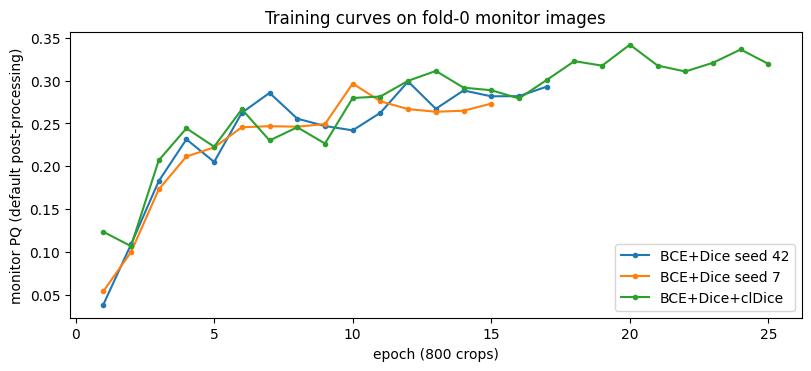

In [6]:
names = {"arch_smp_unet_efficientnet-b3": "BCE+Dice seed 42", "seed2_smp_unet_efficientnet-b3": "BCE+Dice seed 7",
         "cldice_smp_unet_efficientnet-b3": "BCE+Dice+clDice"}
rows = []
for n, lab in names.items():
    r = json.load(open(f"runs/{n}/result.json"))
    rows.append(dict(model=lab, best_epoch=r["best_epoch"], default_monitor=r["monitor_pq"], default_report=r["report_pq"],
                     default_frag=r["report_frag_gt"]))
d = pd.DataFrame(rows)
tuned = pd.DataFrame(cld["table"])[["pp", "monitor_pq", "report_pq", "report_sq", "report_rq", "report_frag_gt"]]
tuned["pp"] = tuned.pp.apply(lambda p: f"{p['threshold']}/{p['min_area']}")
print(pd.concat([d, tuned.add_prefix("tuned_")], axis=1).round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 3.6), constrained_layout=True)
for n, lab in names.items():
    h = pd.read_csv(f"runs/{n}/history.csv"); ax.plot(h.epoch, h.val_pq, marker=".", label=lab)
ax.set_xlabel("epoch (800 crops)"); ax.set_ylabel("monitor PQ (default post-processing)")
ax.set_title("Training curves on fold-0 monitor images"); ax.legend(loc="lower right")
plt.show()

**Interpretation.**
- **clDice does what it is designed to do.** With the default post-processing it scores **0.344** on report
  against 0.309 and 0.314 for the two BCE+Dice seeds (+0.03), and it **fragments fewer filaments: 109** against
  161 and 148. Its raw output is cleaner: fewer broken pieces and fewer tiny blobs.
- **After tuning, most of that advantage is gone.** With each model's own tuned post-processing (all chose
  0.6/500), clDice scores 0.385 on monitor against 0.382 and 0.381 (+0.003), and **0.394 on report, between the
  two seeds** (0.396 and 0.376). Fragmentation is 66 against 69 and 74. The 500-px filter already removes most
  of the small debris that clDice prevents, so the two fixes overlap.
- **Training is slower:** clDice peaked at epoch 20 (25 epochs run), against 12 and 10 for BCE+Dice. The curve
  above shows it still improving after BCE+Dice had stopped.
- **Decision:** clDice was kept for the all-data model (section 6) because it was ahead on monitor, as the rule
  set before the test required. The evidence is weak: +0.003 on monitor is well inside the 0.02 seed spread.

**What & why.** Numbers alone don't show *whether* clDice joins broken filaments. For every fold-0 report image
we score both models (each with its own tuned post-processing). Among the "busy" images (at least 6 expert
filaments; on a one-filament image a single blob decides the whole score) we show the one where clDice gained
the most PQ and the one where it lost the most, zoomed to the region holding the filaments. Each filament gets
its own colour, so a filament broken into pieces shows up as several colours.

clDice better on 33 images, worse on 43, within 0.01 on 23
busy images (>= 6 expert filaments): 61; clDice better on 21, worse on 28


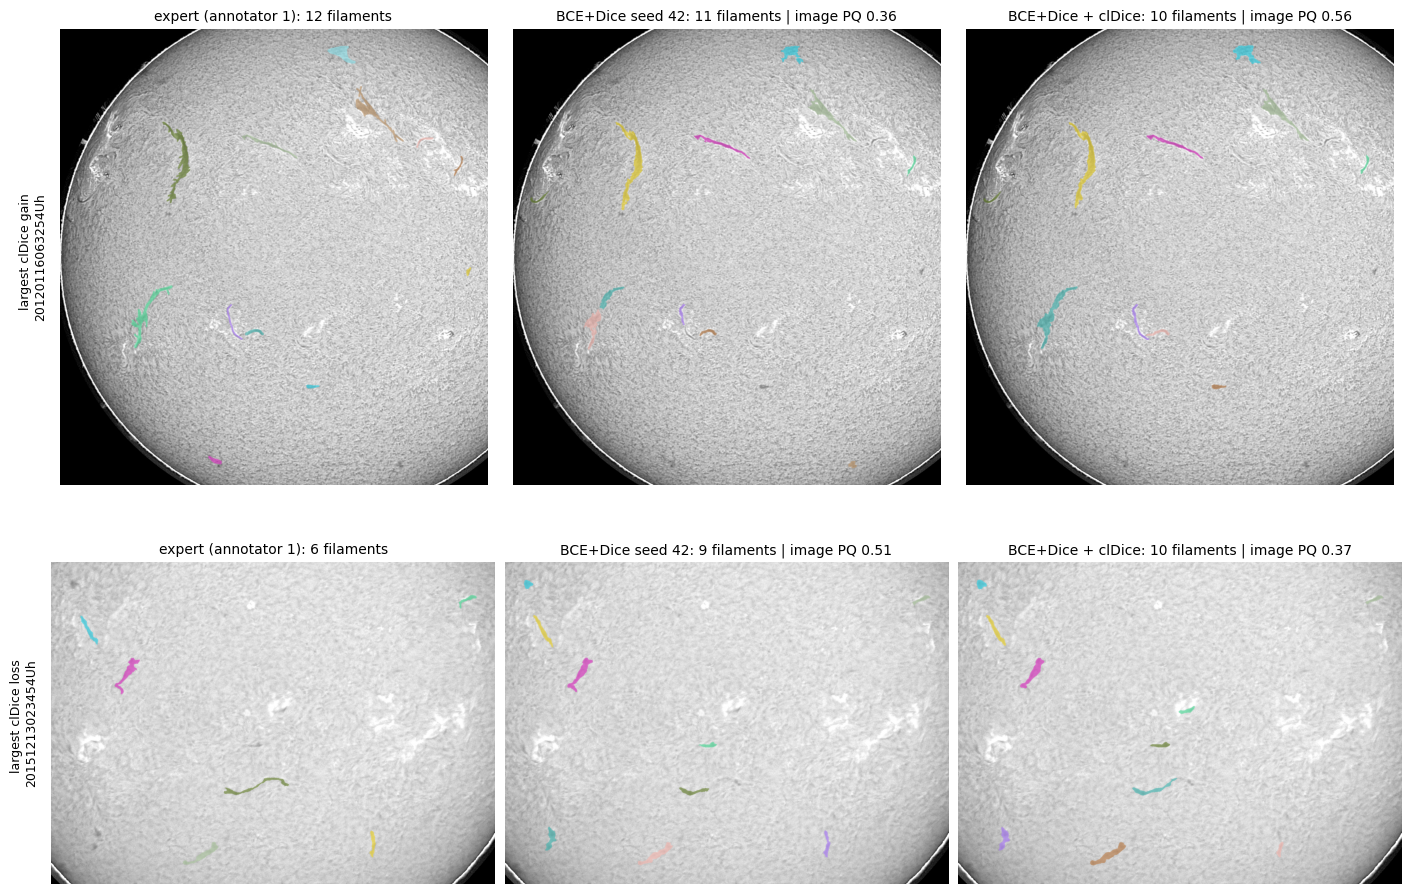

In [7]:
obs_rep = fp.val_observations(fp.Config(prepared_dir=PREPARED), "report")
pmap = {r["kind"]: r["pp"] for r in cld["table"]}
A, B = ("arch_smp_unet_efficientnet-b3", "BCE+Dice seed 42"), ("cldice_smp_unet_efficientnet-b3", "BCE+Dice + clDice")
def per_image(name, pp):
    c = fp.Config(prepared_dir=PREPARED, **pp); out = {}
    for o in obs_rep.itertuples():
        pr = cv2.imread(str(IMP / "probs" / f"{name}_tta1" / f"{o.obs}.png"), cv2.IMREAD_UNCHANGED).astype(np.float32) / 255
        m, _ = fp.score_probs({o.obs: pr}, obs_rep[obs_rep.obs == o.obs], c, details=True); out[o.obs] = m["pq"]
    return pd.Series(out)
pa, pb = per_image(A[0], pmap["bce_dice seed 42"]), per_image(B[0], pmap["bce_dice + clDice"])
diff = (pb - pa).sort_values()
print(f"clDice better on {(diff > 0.01).sum()} images, worse on {(diff < -0.01).sum()}, within 0.01 on {(diff.abs() <= 0.01).sum()}")
sets = pd.read_csv(Path(PREPARED, "train_sets.csv")).groupby("obs").n_inst.mean()
busy = diff[diff.index.map(sets) >= 6]          # images with at least 6 expert filaments (one-filament images say little)
print(f"busy images (>= 6 expert filaments): {len(busy)}; clDice better on {(busy > 0.01).sum()}, worse on {(busy < -0.01).sum()}")
rng = np.random.default_rng(0); cmap = rng.uniform(0.2, 1, (256, 3)); cmap[0] = 0
def colour(inst):
    return cmap[inst.astype(np.int64) % 256]
fig, axes = plt.subplots(2, 3, figsize=(14, 9.5), constrained_layout=True)
for row, stem, tag in zip(axes, [busy.index[-1], busy.index[0]], ["largest clDice gain", "largest clDice loss"]):
    o = obs_rep[obs_rep.obs == stem].iloc[0]; img = fp.load_image(fp.Config(), stem).astype(np.float32) / 255
    gt = np.load(f"cache/inst/{o.set_ids.split('|')[0]}.npy")
    panels = [("expert (annotator 1)", gt)]
    for (name, lab), key in [(A, "bce_dice seed 42"), (B, "bce_dice + clDice")]:
        pr = cv2.imread(str(IMP / "probs" / f"{name}_tta1" / f"{stem}.png"), cv2.IMREAD_UNCHANGED).astype(np.float32) / 255
        panels.append((lab, fp.prob_to_instances(pr, fp.Config(prepared_dir=PREPARED, **pmap[key]))))
    ys, xs = np.nonzero(sum(p[1] > 0 for p in panels))      # zoom to the box holding every filament
    y0, y1, x0, x1 = max(ys.min() - 60, 0), min(ys.max() + 60, 2048), max(xs.min() - 60, 0), min(xs.max() + 60, 2048)
    for ax, (lab, inst) in zip(row, panels):
        over = np.dstack([img] * 3); m = inst > 0; over[m] = 0.35 * over[m] + 0.65 * colour(inst)[m]
        ax.imshow(over[y0:y1, x0:x1]); ax.axis("off")
        n = int(len(np.unique(inst)) - 1)
        extra = "" if lab.startswith("expert") else f" | image PQ {(pa if lab == A[1] else pb)[stem]:.2f}"
        ax.set_title(f"{lab}: {n} filament{'s' if n != 1 else ''}{extra}", fontsize=10)
    row[0].text(-0.03, 0.5, f"{tag}\n{stem}", transform=row[0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
plt.show()

**Interpretation.**
- **Per image, clDice is not better on balance.** It is better on 33 report images, worse on 43, and within
  0.01 on 23. On the 61 busy images it is better on 21 and worse on 28.
- **Top row (largest gain, Udaipur 2012-01-16, image PQ 0.36 → 0.56):** BCE+Dice breaks the long curved
  filament on the left into two pieces (teal and pink). clDice keeps it as one, which is the continuity effect
  we wanted.
- **Bottom row (largest loss, Udaipur 2015-12-13, image PQ 0.51 → 0.37):** clDice predicts 10 filaments where
  the expert drew 6. The extra elongated detections in the centre count as false positives.
- **So clDice trades one error for another.** It joins broken filaments but also turns faint elongated dark
  structures into confident detections. On the pooled score the two effects roughly cancel.

## 6. More training data: retrain on all 707 images
**What & why.** Each fold model trains on 80% of the labelled images. A model trained on all of them sees 25%
more filaments, which usually helps on a new test set. But it leaves no held-out images, so early stopping is
impossible: it must train for a **fixed** number of epochs (cosine learning-rate decay). We can still check that
recipe fairly: train it on folds 1–4 only and score it on fold 0, against the early-stopped model. Two epoch
counts were tried: 12 (median best epoch of the five BCE+Dice fold runs) and 20 (best epoch of the clDice run,
which learned more slowly). The loss is BCE+Dice+clDice because section 5 found it slightly ahead on monitor.
The count with the higher **monitor** PQ was then used for the all-data model.

In [8]:
rc = pd.DataFrame(alld["recipe_check"])
rc["pp"] = rc.pp.apply(lambda p: f"{p['threshold']}/{p['min_area']}")
print(rc[["kind", "pp", "monitor_pq", "report_pq", "report_sq", "report_rq"]].round(4).to_string(index=False))
print(f"\nchosen epochs: {alld['epochs']} | loss: {alld['loss']} | all-data model: {alld['alldata_run']} "
      f"({alld['alldata_minutes']} min to train)")
print(f"fixed-epoch recipe minus early stopping, report PQ: {alld['recipe_gap_report']:+.4f}")

                                                           kind      pp  monitor_pq  report_pq  report_sq  report_rq
early stopping (cldice_smp_unet_efficientnet-b3, best epoch 20) 0.6/500      0.3848     0.3935     0.6703     0.5871
                                     fixed 12 epochs, cosine LR 0.7/500      0.3778     0.3807     0.6652     0.5723
                                     fixed 20 epochs, cosine LR 0.5/500      0.3785     0.3738     0.6658     0.5615

chosen epochs: 20 | loss: bce_dice_cldice | all-data model: alldata_fixed20_bce_dice_cldice (8.71 min to train)
fixed-epoch recipe minus early stopping, report PQ: -0.0197


**Interpretation.**
- **Fixed-epoch training is a bit worse than early stopping.** On the same 80% of the data, 12 epochs give
  monitor 0.378 / report 0.381 and 20 epochs give 0.379 / 0.374, against 0.385 / 0.394 for the early-stopped
  clDice model. The gap is −0.006 on monitor and −0.013 to −0.020 on report.
- That gap is about the size of the seed spread (0.02), so it may be partly bad luck. But it points the same
  way on both image sets and for both epoch counts, so we treat it as a real cost of losing early stopping.
- **The epoch choice was a coin flip:** 20 beat 12 on monitor by 0.0008 and was used, though 12 was better on
  report. Either is defensible.
- **The all-data model** (20 epochs, BCE+Dice+clDice, all 707 images, 8.7 min) has 25% more training data,
  which may make up for the recipe cost, or may not. **Only Kaggle can tell**, because no labelled image is left
  to score it on. It is the least certain of the candidates.

## 7. Candidate submission files
**What & why.** Only changes that helped locally go into a file. Each file below was written by
`run_improve.py` with flip TTA, in the official format (one row per filament, RLE in the original 2048×2048
frame). The upload itself is done by hand on the competition page (5 per day).

In [9]:
old = pd.read_csv("submission.csv")
rows = [dict(file="submission.csv (first upload, Kaggle 0.33)", models="EffB3 s42 (fold 0)", pp="0.6/500", rows=len(old),
             images=old.filament_id.str.rsplit("_", n=1).str[0].nunique(), sec_per_img=pp_old.get("submission_seconds_per_image"))]
for f in subs["files"]:
    p = f["post_processing"]
    rows.append(dict(file=f"submissions/{f['file']}", models=f["note"], pp=f"{p['threshold']}/{p['min_area']}",
                     rows=f["rows"], images=f["images"], sec_per_img=f["seconds_per_image"]))
st = pd.DataFrame(rows); st["filaments_per_image"] = (st.rows / 180).round(1)
print(st.to_string(index=False))
for f in subs["files"]:
    s = pd.read_csv(Path("submissions") / f["file"])
    assert list(s.columns) == ["filament_id", "segmentation_rle"] and s.filament_id.is_unique
print("\nformat check passed for", len(subs["files"]), "files (columns, unique ids)")

                                      file                              models      pp  rows  images  sec_per_img  filaments_per_image
submission.csv (first upload, Kaggle 0.33)                  EffB3 s42 (fold 0) 0.6/500  1474     179         2.11                  8.2
               submissions/sub_alldata.csv one model trained on all 707 images 0.5/500  1726     179         2.02                  9.6
        submissions/sub_5fold_ensemble.csv        average of the 5 fold models 0.5/500  1518     179         9.24                  8.4
    submissions/sub_alldata_plus_5fold.csv      all-data model + 5 fold models 0.5/500  1538     179        11.06                  8.5

format check passed for 3 files (columns, unique ids)


**Interpretation.**
- All three new files have the official columns and unique ids. Like the first upload, each covers 179 of the
  180 test images: one image gets no filament from any model, and an image with no rows is allowed.
- **Filaments per image:** the ensembles predict 8.4–8.5, close to the first upload (8.2) and to the experts
  (7.5 on average). The all-data model predicts **9.6**, which fits section 5: clDice adds extra detections.
- **Inference time:** 2.0 s per image (one model), 9.2 s (5 models), 11.1 s (6 models).

**Suggested upload order** (one per slot; compare each with 0.33):
1. `sub_5fold_ensemble.csv`, the best supported. Ensembling helped fairly on fold 0 (+0.013 over the average
   single run), and the fold models score 0.343–0.393 on their own held-out images.
2. `sub_alldata_plus_5fold.csv`, the same ensemble plus the all-data model at 1/6 weight. It is low risk and
   adds the extra data.
3. `sub_alldata.csv`, one model, the least certain (section 6).

A caution for reading the leaderboard: the public score uses ~90 images, and our fold-to-fold standard
deviation on ~100 images is 0.019. Differences of about 0.02 or less between uploads may be noise.

## Summary
| Change | Local evidence (report PQ) | Adopted? |
|---|---|---|
| Fair 5-fold estimate (tuned 0.5/500 + TTA) | **0.368 ± 0.019** (fold 0 was the best fold at 0.393); default settings 0.298 | Basis for every comparison |
| Small-blob rule | +0.0007 monitor, +0.0027 report; every less strict setting hurts | **No** (below the +0.002 bar) |
| Ensemble of 3 EfficientNet-B3 runs | **0.399** vs 0.376–0.396 single (mean 0.386); 3× inference time | **Yes**: 5-fold ensemble file |
| clDice loss (continuity) | Default settings +0.03, fragmented filaments 161 → 109; after tuning 0.394, within seed spread | Kept for the all-data model; weak evidence |
| All 707 images, fixed 20 epochs | Fixed-epoch recipe −0.006 monitor / −0.020 report vs early stopping (on 80%) | Candidate file only; only Kaggle can judge |

**Main takeaways**
1. **The Kaggle drop is mostly expected.** A fair estimate of the first submission is 0.368, not 0.396, and
   Kaggle's 0.33 is within about two fold standard deviations of it.
2. **The biggest measured gain is ensembling**, mainly because it removes the ±0.01 seed lottery of a single
   model.
3. **clDice joins broken filaments** (fragmentation 161 → 109 with default settings) but adds false elongated
   detections. After tuning it is no better on PQ.
4. **Small filaments stay unsolved.** The model's confidence cannot tell real small filaments from false ones.